In [268]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import lstsq
from src.InverseHeatModel import InverseHeatModel

import torch
import torch.nn as nn

from src.print_utils import print_kv, print_section, print_table_header, print_table_row, print_line
from src.window_manager import make_windows, window_loss_full, window_loss_single

device = "cuda" if torch.cuda.is_available() else "cpu"



plt.style.use("styles/plots.mplstyle")

In [269]:
def convolutivity_test(F,G):
    H = np.divide(G, F, where=(np.abs(F) > 1e-10), 
                       out=np.zeros_like(G))

    error_diag = np.linalg.norm(H * F - G)**2
    
    return H,error_diag

In [270]:
np.random.seed(42)

dati = np.genfromtxt(
    f"dataset/dataset_eltek/2 Piastre/2026-07-20_Prova Housing -  4 termocoppie(T3 su S1)_ 2 Piastre_Prova 1(.).txt",
    delimiter=";",
    usecols=(0,1,2,3)
)

low_idx = 0
high_idx= -1

T_amb = np.mean(dati[0:10000,0])
Theta_0 = dati[low_idx:high_idx,0] - T_amb # misura sensore
Theta_1 = dati[low_idx:high_idx,1] - T_amb 
Theta_2 = dati[low_idx:high_idx,2] - T_amb # temperatura reale
Theta_3 = dati[low_idx:high_idx,3] - T_amb # sensore

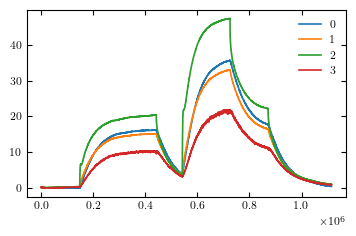

In [271]:
plt.plot(Theta_0, label="0")
plt.plot(Theta_1, label="1")
plt.plot(Theta_2, label="2")
plt.plot(Theta_3, label="3")

plt.legend()

In [272]:
nt = np.size(Theta_2)
n = int(2 * nt - 1)
  
f1 = Theta_2
g1 = Theta_3

F = np.fft.rfft(f1, n=n)
G = np.fft.rfft(g1, n=n)
H,loss = convolutivity_test(F,G)

h = np.fft.irfft(H,n=n)
print(loss)


4.0909205857958026e-19


In [273]:
dati = np.genfromtxt(
    f"dataset/dataset_eltek/2 Piastre/2026-07-21_Prova Housing -  4 termocoppie(T3 su S1)_ 2 Piastre_Prova 2(.).txt",
    delimiter=";",
    usecols=(0,1,2,3)
)

low_idx = 0
high_idx= -1

T_amb = np.mean(dati[0:10000,0])
Theta_0 = dati[low_idx:high_idx,0] - T_amb # misura sensore
Theta_1 = dati[low_idx:high_idx,1] - T_amb 
Theta_2 = dati[low_idx:high_idx,2] - T_amb # temperatura reale
Theta_3 = dati[low_idx:high_idx,3] - T_amb # sensore

In [274]:
def make_pairs(
    g_wins: torch.Tensor,   # (n_samples, n_windows, W)
    f_wins: torch.Tensor,   # (n_samples, n_windows, W)
) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
    """
    Args:
        g_wins (torch.Tensor):
            shape (n_samples, n_windows, W)
            
        f_wins (torch.Tensor):
            shape (n_samples, n_windows, W)

    Returns:
        (tuple[torch.Tensor, torch.Tensor, torch.Tensor]))
    """
    n_samples, n_windows, W = g_wins.shape

    
    g_prev_first = torch.zeros(n_samples, 1, W,
                               dtype=g_wins.dtype, device=g_wins.device)

    if n_windows > 1:
        g_prev = torch.cat([g_prev_first, g_wins[:, :-1, :]], dim=1)
    else:
        g_prev = g_prev_first

    return (
        g_prev.reshape(-1, W),
        g_wins.reshape(-1, W),
        f_wins.reshape(-1, W),
    )

In [275]:
import math

def train(
    model,
    g_tr_prev, 
    g_tr_cur, 
    f_tr_cur,
    g_va_prev, 
    g_va_cur, 
    f_va_cur,
    W,
    n_epochs:           int   = 2000,
    batch_size:         int   = 64,
    lr:                 float = 1e-3,
    weight_decay:       float = 0.0,
    checkpoint_path:    str   = "assets/tikhonov_learned/best_tikhonov.pt",
    log_every:          int   = 100,
    save_every:         int   = 100,
    history:            dict[str, list] = None
) -> dict:
    """
    Training loop with non-overlapping windows.

    Args:
        model (InverseHeatModel):
            Model to train.

        g_tr_wins (np.ndarray):
            Training input windows with shape
            (n_samples, n_windows, W).

        f_tr_wins (np.ndarray):
            Training target windows with shape
            (n_samples, n_windows, W).

        g_va_wins (np.ndarray):
            Validation input windows with shape
            (n_samples, n_windows, W).

        f_va_wins (np.ndarray):
            Validation target windows with shape
            (n_samples, n_windows, W).

    Returns:
        dict[str, list[float]]:
            Dictionary containing:
                - "train_loss": training loss history
                - "val_loss": validation loss history
                - "lr": learning rate history
    """
    
    N_pairs = g_tr_cur.shape[0]
    print_line(char='=')
    print_kv("Number of pairs",N_pairs)
    print_kv("Batch Size:", batch_size)
    
    optimizer = torch.optim.Adam(
        model.parameters(), lr=lr, weight_decay=weight_decay
    )
    
    scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
        optimizer, T_0=2000, T_mult=2, eta_min=1e-6
    )
    
    loss_fn = nn.MSELoss()
    
    if history is None:
        history     = {"train_loss": [], "val_loss": [], "lr": []}
    best_val    = float("inf")
    
    print_line(char='=')
    print_table_header([
                "Epoch",
                "Train Loss",
                "Val Loss",
                "LR"
                ])
    print_line()
    
    for epoch in range(1, n_epochs + 1):
        
        permutation = torch.randperm(N_pairs, device=g_tr_cur.device)
        
        # Training: mini-batch loop
        model.train()
        train_acc = 0.0
        
        for start in range(0, N_pairs, batch_size):
            idx = permutation[start : start + batch_size]
            optimizer.zero_grad()
            loss = window_loss_single(
                model,
                g_tr_cur[idx], g_tr_prev[idx], f_tr_cur[idx],
                loss_fn
            )
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            train_acc += loss.item()

        train_l = train_acc / math.ceil(N_pairs / batch_size)
        
        # Validation: full-batch
        model.eval()
        with torch.no_grad():
            val_l = window_loss_single(
                model, g_va_cur, g_va_prev, f_va_cur, loss_fn
            ).item()
        
        scheduler.step(epoch)
        current_lr = optimizer.param_groups[0]["lr"]
 
        history["train_loss"].append(train_l)
        history["val_loss"].append(val_l)
        history["lr"].append(current_lr)

        # Save checkpoint if the current validation loss is less then the previous one.
        # In this case update the min validation loss
        if epoch % save_every == 0 or epoch == n_epochs:
            if val_l < best_val:
                best_val = val_l
                torch.save(
                    {
                        "epoch":           epoch,
                        "model_state":     model.state_dict(),
                        "optimizer_state": optimizer.state_dict(),
                        "val_loss":        best_val,
                        "W":               W,
                    },
                    checkpoint_path,
                )
 
        if epoch % log_every == 0 or epoch == 1:
            
            print_table_row([
                f"{epoch}/{n_epochs}",
                f"{train_l:.2e}",
                f"{val_l:.2e}",
                f"{current_lr:.2e}"]
            )
    
    print_line(char='=')
    return history

In [276]:
g_obs = g1
f_real = f1

W = 300
n_windows = nt // W 
nW = int(2 * W - 1)
print_kv("W         [sample]"   , f"{W}")
print_kv("n_windows"            , f"{n_windows}")

# ---- Load dataset ----------------------
f_all = f_real.astype(np.float32)
g_all = g_obs.astype(np.float32)

f_all = np.expand_dims(f_all, axis=0)
g_all = np.expand_dims(g_all, axis=0)
f_all = torch.from_numpy(f_all).to(device)
g_all = torch.from_numpy(g_all).to(device)

g_wins, f_wins = make_windows(g_all ,f_all   ,W)

print(np.shape(g_wins))

# Build pairs (g_prev, g_cur)
g_prev, g_cur, f_cur = make_pairs(g_wins, f_wins)
print(np.shape(g_prev))
VAL_FRACTION = 0.1
rng = np.random.default_rng(42)
idx = rng.permutation(n_windows)
n_val = max(1, int(VAL_FRACTION * n_windows))
idx_val = idx[:n_val]
idx_train = idx[n_val:]

g_tr_prev = g_prev[idx_train]
g_tr_cur = g_cur[idx_train]
f_tr_cur = f_cur[idx_train]

g_val_prev = g_prev[idx_val]
g_val_cur = g_cur[idx_val]
f_val_cur = f_cur[idx_val]


W         [sample]                                                 300
n_windows                                                         3716
torch.Size([1, 3716, 300])
torch.Size([3716, 300])


In [ ]:
h_cut = h[:W]
H_cut = np.fft.rfft(h_cut,nW)

model = InverseHeatModel(H=H_cut, nt=W, dt=0.01, M=2).to(device)
model.summary()

Structure                                                  nk=300  M=2
----------------------------------------------------------------------
Total Parameters                                                 2,100
Trainable                                                        2,100
Frozen                                                               0
----------------------------------------------------------------------
Log_R                                                            Learn
Phi                                                              Learn
Diagonal                                                         Learn
m=1                                                              Learn
m=2                                                              Learn
----------------------------------------------------------------------
Non-zero elements                                         1,494/90,000
Sparsity                                                         98.3%


In [ ]:
DOTRAINING = False
model.sigma.increase_bandwidth(model,8)
model.summary()
if DOTRAINING:
    history = train(
        model = model,
        g_tr_prev = g_tr_prev,   
        g_tr_cur = g_tr_cur,
        f_tr_cur = f_tr_cur,
        g_va_prev = g_val_prev,   
        g_va_cur = g_val_cur,
        f_va_cur = f_val_cur,
        W = W,
        batch_size=256,
        n_epochs     = 500,
        checkpoint_path = f"assets/tikhonov_learned/best_tikhonov.pt",
        log_every    = 10
    )
else:
    ckpt = torch.load("assets/tikhonov_learned/best_tikhonov.pt", map_location="cpu")
    model.load_state_dict(ckpt["model_state"])
    model.to(device)
    print_kv("Model preloaded", "assets/tikhonov_learned/best_tikhonov.pt")


Structure                                                  nk=300  M=8
----------------------------------------------------------------------
Total Parameters                                                 5,700
Trainable                                                        5,700
Frozen                                                               0
----------------------------------------------------------------------
Log_R                                                            Learn
Phi                                                              Learn
Diagonal                                                         Learn
m=1                                                              Learn
m=2                                                              Learn
m=3                                                              Learn
m=4                                                              Learn
m=5                                                              Learn
m=6   

In [ ]:
g_prev = g_val_prev
g_cur = g_val_cur

f_rec = model(g_cur, g_prev).to("cpu").asnumpy()

plt.plot(f_rec)

AttributeError: 'Tensor' object has no attribute 'asnumpy'

/home/simone/anaconda3/envs/thesis_env/lib/python3.10/site-packages/IPython/core/events.py:82: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)


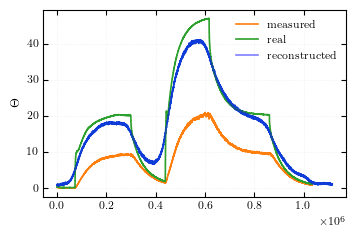

In [ ]:
g = Theta_3
f = Theta_2

g_trap = np.empty_like(g)
g_trap[:-1] = (g[:-1] + g[1:]) / 2
g_trap[-1] = g[-1] / 2
                
G = np.fft.rfft(g_trap, n)
F = np.fft.rfft(f, n=n)

lambda_reg = 50

omegas = np.fft.rfftfreq(n, d=0.01) * 2 * np.pi
H_power = np.abs(H)**2
eps = 1e-6 * np.max(H_power)

W = np.conjugate(H) / (np.abs(H)**2 + lambda_reg*omegas**2 + eps)

F_rec = W*G/0.01/2
f_rec = np.fft.irfft(F_rec,n=n)[:nt]

plt.figure(1)
plt.plot(f_rec)

plt.plot(g, label="measured")
plt.plot(f, label="real")
plt.plot(f_rec, label="reconstructed", c="b", alpha=0.5)

plt.ylabel(r"$\Theta$")
plt.grid(True, alpha=0.3)
        
plt.legend()